In [1]:
import pandas as pd


In [2]:
df = pd.read_csv('uber.csv')

In [3]:
df.head()


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [7]:
print(df.shape)

(200000, 9)


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [9]:
# Remove unnecessary columns
df.drop(columns=['key', 'Unnamed: 0'], inplace=True, errors='ignore')

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert datetime
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

# Remove missing values
df.dropna(inplace=True)

# Remove invalid records
df = df[df['fare_amount'] > 0]
df = df[df['passenger_count'].between(1, 6)]

df = df[
    df['pickup_latitude'].between(40, 42) &
    df['dropoff_latitude'].between(40, 42) &
    df['pickup_longitude'].between(-75, -72) &
    df['dropoff_longitude'].between(-75, -72)
]

print("Data after preprocessing:", df.shape)

Data after preprocessing: (195100, 7)


In [10]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat/2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon/2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


df['distance'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

print(df[['distance', 'fare_amount']].head())

   distance  fare_amount
0  1.683323          7.5
1  2.457590          7.7
2  5.036377         12.9
3  1.661683          5.3
4  4.475450         16.0


In [11]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

Lower limit: -3.75
Upper limit: 22.25


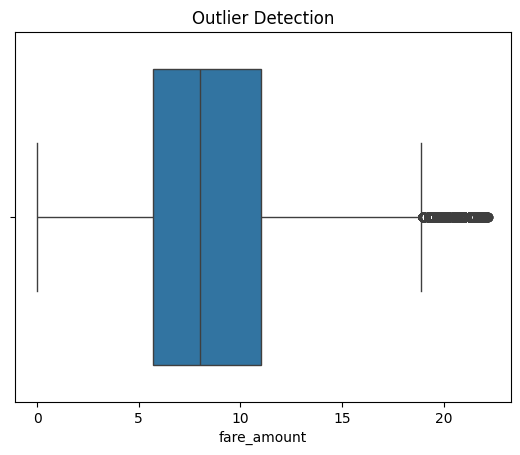

In [12]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

sns.boxplot(x=df['fare_amount'])
plt.title("Outlier Detection")
plt.show()

                 fare_amount  distance  passenger_count      hour       day  \
fare_amount         1.000000  0.706127         0.012437 -0.012952  0.006977   
distance            0.706127  1.000000        -0.000633 -0.031684  0.006052   
passenger_count     0.012437 -0.000633         1.000000  0.015213  0.002666   
hour               -0.012952 -0.031684         0.015213  1.000000  0.005348   
day                 0.006977  0.006052         0.002666  0.005348  1.000000   
month               0.026859  0.004622         0.008616 -0.003042 -0.016164   
year                0.135965 -0.033174         0.003058  0.002750 -0.010546   

                    month      year  
fare_amount      0.026859  0.135965  
distance         0.004622 -0.033174  
passenger_count  0.008616  0.003058  
hour            -0.003042  0.002750  
day             -0.016164 -0.010546  
month            1.000000 -0.115363  
year            -0.115363  1.000000  


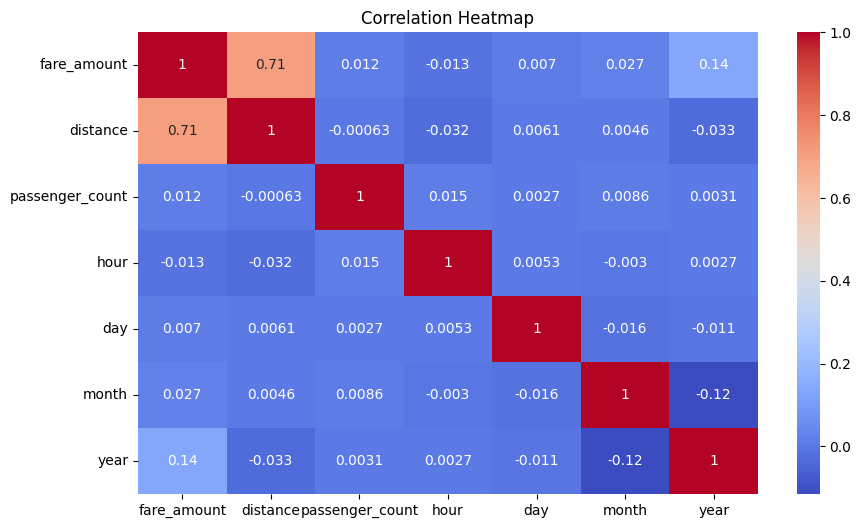

In [13]:
corr = df[
    ['fare_amount', 'distance', 'passenger_count',
     'hour', 'day', 'month', 'year']
].corr()

print(corr)

plt.figure(figsize=(10, 6))

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

In [14]:
X = df[
    ['distance', 'passenger_count',
     'hour', 'day', 'month', 'year']
]

y = df['fare_amount']

print(X.head())
print(y.head())

   distance  passenger_count  hour  day  month  year
0  1.683323                1    19    7      5  2015
1  2.457590                1    20   17      7  2009
2  5.036377                1    21   24      8  2009
3  1.661683                3     8   26      6  2009
4  4.475450                5    17   28      8  2014
0     7.5
1     7.7
2    12.9
3     5.3
4    16.0
Name: fare_amount, dtype: float64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142713, 6)
Testing data: (35679, 6)


In [16]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

r2_lr = r2_score(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

mae_lr = mean_absolute_error(y_test, y_pred_lr)

print("Linear Regression")
print("R2 Score:", r2_lr)
print("RMSE:", rmse_lr)
print("MAE:", mae_lr)

Linear Regression
R2 Score: 0.45116699053916864
RMSE: 3.0684915660369576
MAE: 1.8345097341917171


In [17]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("Random Forest Regression")
print("R2 Score:", r2_rf)
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)

Random Forest Regression
R2 Score: 0.7220416507354244
RMSE: 2.183708596786604
MAE: 1.5476569195698684


In [18]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [r2_lr, r2_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'MAE': [mae_lr, mae_rf]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.451167  3.068492  1.834510
1      Random Forest  0.722042  2.183709  1.547657


In [19]:
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)

print("Predicted Fare:", prediction[0])

print("Actual Fare:", y_test.iloc[0])

Predicted Fare: 9.462000000000003
Actual Fare: 8.1


In [20]:
if r2_rf > r2_lr and rmse_rf < rmse_lr:
    print("Random Forest performs better")
else:
    print("Linear Regression performs better or results are mixed")

Random Forest performs better
